# Day 04 · Can CLIP Read Architectural Style?

Take about 50 building photos and let **CLIP** (`open_clip`) guess each one's style from text labels like *"a photo of a gothic building"*, with no training (zero-shot). Then make a grid grouped by predicted style and find the funniest mistake.

**Data:** [Architecture dataset on Kaggle](https://www.kaggle.com/datasets/wwymak/architecture-dataset), a mirror of Zhe Xu's ECCV 2014 architectural style dataset (25 styles, images from Wikimedia Commons).

**No full download:** the dataset is 1.4 GB, but we only need ~50 photos. We list its files through Kaggle's API and download just the ones we sample (≈5 MB). They're cached in `~/.cache/kagglehub`, outside the repo, so nothing large ever gets committed.

**Stack:** Python · kagglehub · open_clip · PIL

## Step 1 · List the dataset's files (no download)

Kaggle's API returns the file list page by page. Each file path looks like `arcDataset/<Style>/<image>.jpg`, so the folder name is the **true label**.

In [1]:
import os, requests
from collections import defaultdict

HANDLE = "wwymak/architecture-dataset"
API = f"https://www.kaggle.com/api/v1/datasets/list/{HANDLE}"
IMG_EXT = (".jpg", ".jpeg", ".png")
HEADERS = {"User-Agent": "clip-style-demo/0.1"}   # Kaggle returns 404 to the default python-requests agent

import json, time

def get_page(params, tries=6):
    for i in range(tries):
        resp = requests.get(API, params=params, headers=HEADERS, timeout=30)
        if resp.ok:
            return resp.json()
        time.sleep(2 ** i)          # Kaggle rate-limits fast paging, so back off and retry
    resp.raise_for_status()

if os.path.exists("file_list.json"):   # cached after the first run
    files = json.load(open("file_list.json"))
else:
    files, token = [], None
    while True:
        params = {"pageSize": 200}
        if token:
            params["pageToken"] = token
        r = get_page(params)
        files += [f["name"] for f in r.get("datasetFiles", [])]
        token = r.get("nextPageTokenNullable") or r.get("nextPageToken")
        if not token:
            break
        time.sleep(0.5)
    json.dump(files, open("file_list.json", "w"))

# The dataset stores every image twice (arcDataset/ and arcdataset/arcDataset/), so keep one copy.
# Names containing "%" fail to download through kagglehub, so skip those too.
styles, seen = defaultdict(list), set()
for f in sorted(files):
    parts = f.split("/")
    if len(parts) >= 3 and f.lower().endswith(IMG_EXT) and "%" not in f:
        key = (parts[-2], parts[-1])
        if key not in seen:
            seen.add(key)
            styles[parts[-2]].append(f)

print(f"{len(styles)} styles, {sum(len(v) for v in styles.values())} images\n")
for name, imgs in sorted(styles.items(), key=lambda kv: -len(kv[1])):
    print(f"{len(imgs):>5}  {name}")

25 styles, 3338 images

  295  Queen Anne architecture
  257  Art Deco architecture
  253  Greek Revival architecture
  218  Art Nouveau architecture
  199  Ancient Egyptian architecture
  176  Novelty architecture
  166  International style
  154  Baroque architecture
  153  Deconstructivism
  136  Colonial architecture
  130  Beaux-Arts architecture
  125  Georgian architecture
  124  Postmodern architecture
  109  Gothic architecture
   97  Chicago school architecture
   91  Russian Revival architecture
   90  Tudor Revival architecture
   86  Byzantine architecture
   85  Romanesque architecture
   81  American craftsman style
   76  Palladian architecture
   72  Bauhaus architecture
   67  Achaemenid architecture
   52  Edwardian architecture
   46  American Foursquare architecture


## Step 2 · Sample ~50 photos and download only those

7 styles × 7 photos. `random.seed(4)` keeps the sample the same every run. Edit `PICK` using folder names from the list above.

In [2]:
import random, kagglehub

PICK = [
    "Gothic architecture",
    "Art Deco architecture",
    "Bauhaus architecture",
    "Deconstructivism",
    "Baroque architecture",
    "Ancient Egyptian architecture",
    "Novelty architecture",
]
PER_STYLE = 7

random.seed(4)
sample = []
for s in PICK:
    for f in random.sample(styles[s], min(PER_STYLE, len(styles[s]))):
        local = kagglehub.dataset_download(HANDLE, path=f)   # downloads just this one file
        sample.append({"file": local, "true": s})

print(len(sample), "photos ready")

/Users/snehashenoy/Downloads/100-days-ai-arch/day-04-clip-style-classifier/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


49 photos ready


## Step 3 · Ask CLIP

CLIP turns every image and every phrase into a vector, and the phrase whose vector is closest wins.

- **Labels** are the 7 sampled styles **plus 4 modern styles that aren't in the sample** (brutalist, parametric, high-tech, vernacular). Any photo labelled with one of those is guaranteed wrong, and those are usually the funny ones.
- Model: `ViT-B-32` trained on LAION-2B. It runs on the Mac GPU (`mps`), and the first run downloads ~600 MB of weights.

In [3]:
import torch, open_clip
from PIL import Image

def short(s):
    return s.replace(" architecture", "").replace("Deconstructivism", "deconstructivist").lower()

LABELS = [short(s) for s in PICK] + ["brutalist", "parametric", "high-tech", "vernacular"]

device = "mps" if torch.backends.mps.is_available() else "cpu"
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32", pretrained="laion2b_s34b_b79k", device=device)
model.eval()
tokenizer = open_clip.get_tokenizer("ViT-B-32")

with torch.no_grad():
    text = model.encode_text(tokenizer([f"a photo of a {l} building" for l in LABELS]).to(device))
    text /= text.norm(dim=-1, keepdim=True)

for x in sample:
    img = preprocess(Image.open(x["file"]).convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        f = model.encode_image(img)
        f /= f.norm(dim=-1, keepdim=True)
        probs = (100 * f @ text.T).softmax(dim=-1)[0].cpu()
    i = int(probs.argmax())
    x["pred"], x["conf"], x["true_s"] = LABELS[i], float(probs[i]), short(x["true"])

correct = sum(x["pred"] == x["true_s"] for x in sample)
print(f"CLIP accuracy: {correct}/{len(sample)} ({correct/len(sample):.0%})\n")
for l in LABELS:
    n = [x for x in sample if x["true_s"] == l]
    if n:
        print(f"{l:<18} {sum(x['pred'] == l for x in n)}/{len(n)}")

CLIP accuracy: 36/49 (73%)

gothic             7/7
art deco           4/7
bauhaus            4/7
deconstructivist   1/7
baroque            6/7
ancient egyptian   7/7
novelty            7/7


## Step 4 · Grid grouped by predicted style

One row per **predicted** style. A **red border** means CLIP got it wrong, and the caption shows what the building really is.

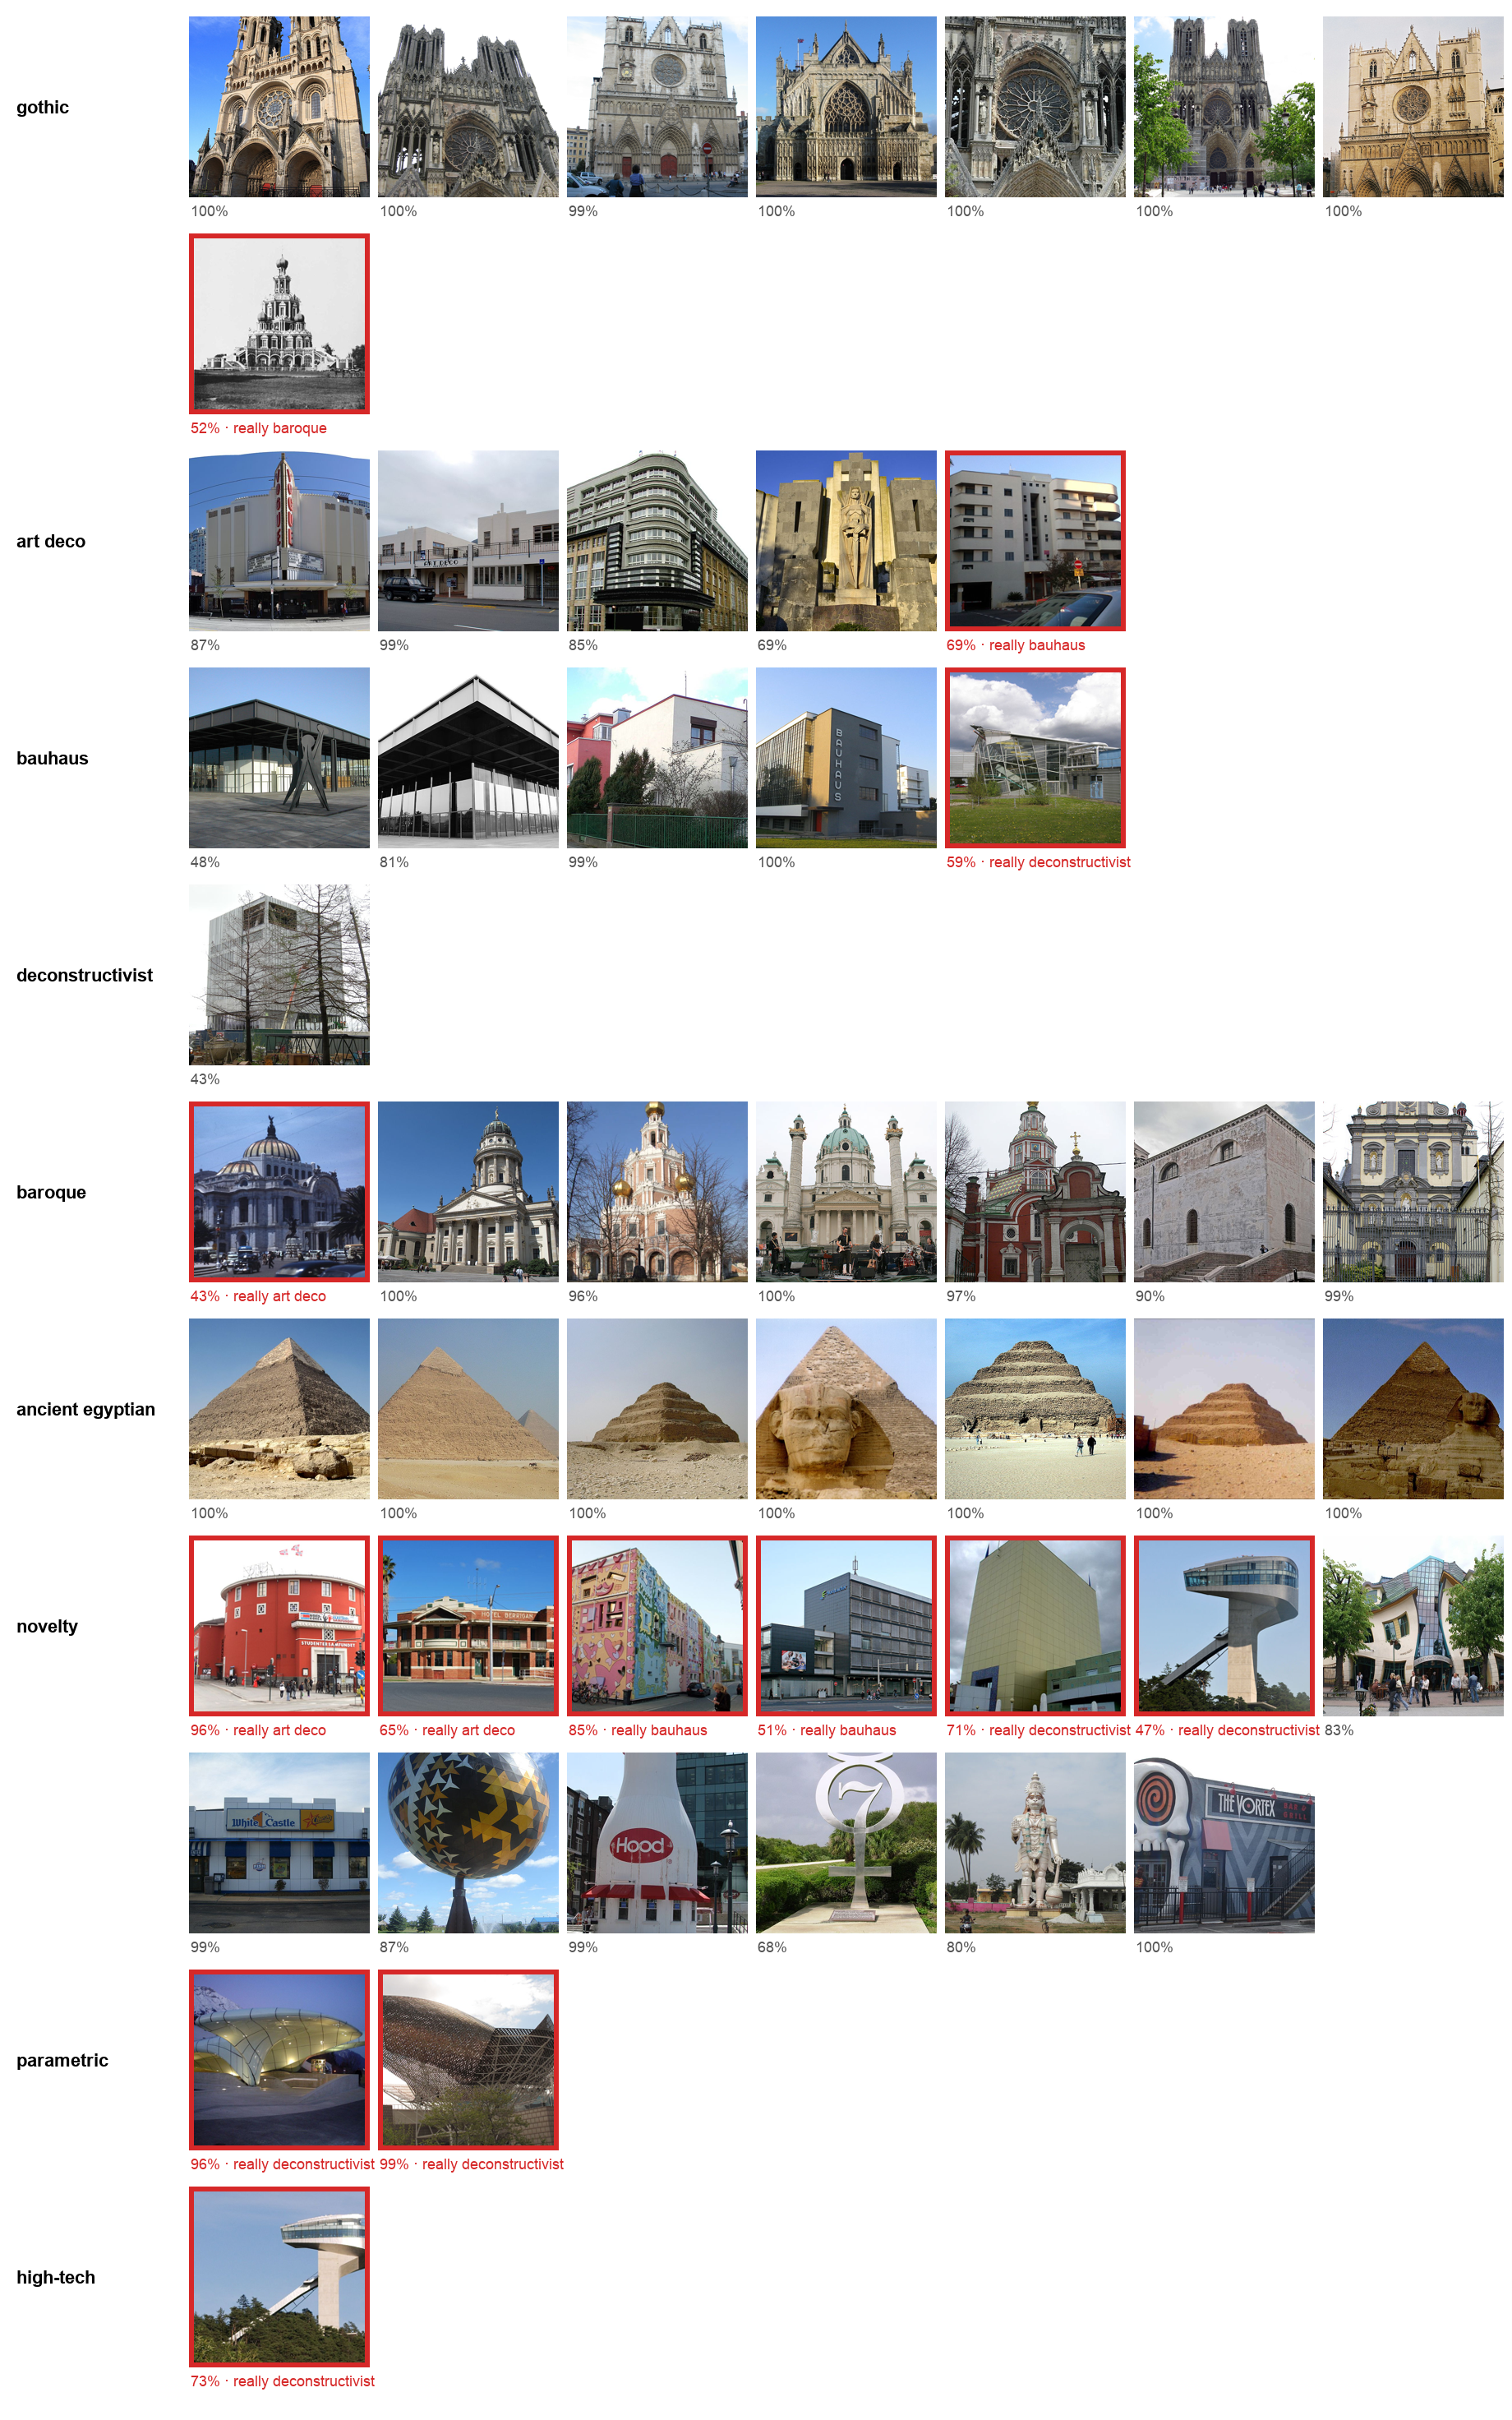

In [4]:
from PIL import ImageDraw, ImageOps, ImageFont

T, PAD, COLS, LEFT = 220, 10, 7, 230
try:
    font = ImageFont.truetype("/System/Library/Fonts/Supplemental/Arial.ttf", 18)
    big = ImageFont.truetype("/System/Library/Fonts/Supplemental/Arial Bold.ttf", 22)
except OSError:
    font = big = ImageFont.load_default()

groups = [(l, [x for x in sample if x["pred"] == l]) for l in LABELS]
groups = [(l, xs) for l, xs in groups if xs]
row_h = T + 34 + PAD
n_rows = sum((len(xs) + COLS - 1) // COLS for _, xs in groups)
W, H = LEFT + COLS * (T + PAD), n_rows * row_h + 40
sheet = Image.new("RGB", (W, H), "white")
d = ImageDraw.Draw(sheet)

y = 20
for label, xs in groups:
    d.text((20, y + T // 2 - 12), label, fill="black", font=big)
    for j, x in enumerate(xs):
        cx, cy = LEFT + (j % COLS) * (T + PAD), y + (j // COLS) * row_h
        thumb = ImageOps.fit(Image.open(x["file"]).convert("RGB"), (T, T))
        wrong = x["pred"] != x["true_s"]
        if wrong:
            thumb = ImageOps.expand(ImageOps.fit(thumb, (T - 12, T - 12)), 6, fill="#D62828")
        sheet.paste(thumb, (cx, cy))
        cap = f"{x['conf']:.0%} · really {x['true_s']}" if wrong else f"{x['conf']:.0%}"
        d.text((cx + 2, cy + T + 6), cap, fill="#D62828" if wrong else "#555", font=font)
    y += ((len(xs) + COLS - 1) // COLS) * row_h

sheet.save("style_grid.png")
sheet

## Step 5 · The funniest errors

Wrong guesses sorted by **how confident** CLIP was. The top one is the post.

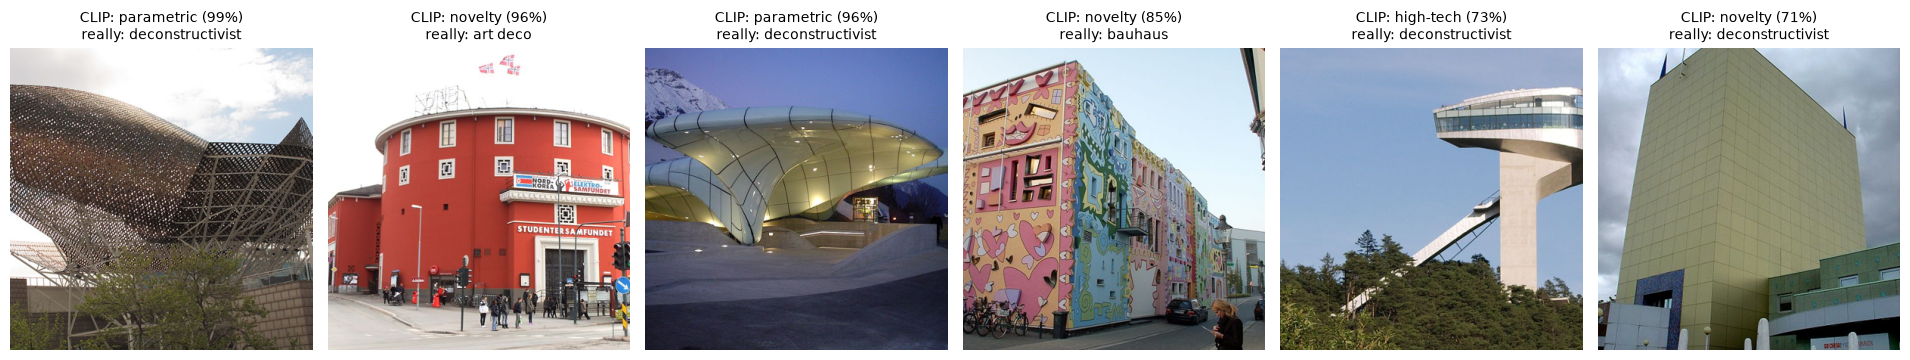

In [5]:
import matplotlib.pyplot as plt

wrong = sorted([x for x in sample if x["pred"] != x["true_s"]], key=lambda x: -x["conf"])[:6]
fig, axes = plt.subplots(1, len(wrong), figsize=(3.2 * len(wrong), 3.8))
for ax, x in zip(axes, wrong):
    ax.imshow(ImageOps.fit(Image.open(x["file"]).convert("RGB"), (400, 400)))
    ax.set_title(f"CLIP: {x['pred']} ({x['conf']:.0%})\nreally: {x['true_s']}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig("funniest_errors.png", dpi=150, bbox_inches="tight")
plt.show()

## What I'd do with more time (but didn't)

- Better prompts (prompt ensembling: *"a photo of a … building"*, *"… architecture"*, *"a … facade"*) usually add several points of accuracy
- Larger CLIP (`ViT-L-14`) vs small, and a comparison of the two
- A confusion matrix showing which styles CLIP mixes up
- A linear probe: train a tiny classifier on CLIP features with ~20 images per style